## 1 Setup and scope

<div dir="ltr" lang="en">VOiCES background condition classification and pretrained Silero VAD. The background task predicts the recording condition, not annotated event onset and offset times. No results are prefilled. CPU is sufficient.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">الهدف هو تصنيف نوع الخلفية في بيانات فويسز، وتحديد فترات الكلام باستخدام نموذج سيليرو المدرّب مسبقًا. تصنيف الخلفية هنا لا يعني تحديد بداية ونهاية أحداث صوتية بمرجع زمني. لا توجد نتائج مفترضة، والتشغيل على المعالج يكفي.</div>

In [2]:
%pip -q install librosa soundfile scikit-learn pandas matplotlib requests tqdm silero-vad
import re, json, time, tarfile, shutil, hashlib, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import requests
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Audio
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay
SEED=42
ROOT=Path('/content/VOICES_mini'); ROOT.mkdir(exist_ok=True)
OUT=Path('/content/VOICES_results'); OUT.mkdir(exist_ok=True)
LABELS=['none','musi','tele','babb']
NAMES={'none':'No added distractor','musi':'Music','tele':'Television','babb':'Babble'}
print('Ali Nasif Jasim | 404131076 | Digital Speech Processing')
print('Python:',platform.python_version(),'Torch:',torch.__version__)

Ali Nasif Jasim | 404131076 | Digital Speech Processing
Python: 3.13.18 Torch: 2.11.0+cpu


## 2 Data access settings

<div dir="ltr" lang="en">The official devkit archive is approximately 27.5 GiB compressed. Streaming avoids saving the full archive, but may still transfer most or all of it. The code retains a small subset and stops when its quotas are satisfied. Existing local VOiCES WAV files can be used instead. Do not use Run all until you understand this download size.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">أرشيف التطوير الرسمي حجمه نحو ٢٧٫٥ جيبيبايت مضغوطًا. القراءة المتتابعة لا تحفظ الأرشيف كاملًا، لكنها قد تستهلك أغلب حجمه أو كله من الإنترنت. نحتفظ بعينة صغيرة ونوقف القراءة عند اكتمال الحصص. يمكن استخدام ملفات أصلية موجودة مسبقًا بدل التنزيل. اقرأ هذا قبل تشغيل جميع الخلايا.</div>

In [3]:
DATA_MODE='stream'  # 'stream' or 'local'
# For local mode, use an extracted VOiCES root with original paths/names.
LOCAL_ROOT=Path('/content/drive/MyDrive/VOiCES_devkit')
ARCHIVE_URL='https://lab41openaudiocorpus.s3.amazonaws.com/VOiCES_devkit.tar.gz'
TARGET={'train':20,'test':10}  # per background; at most one file per speaker/class
MAX_TRANSFER_GIB=30
MAX_WAV_MB=20
print('Mode:',DATA_MODE)
print('Target: 80 training and 40 test recordings across four classes.')
print('Transfer ceiling:',MAX_TRANSFER_GIB,'GiB; retained WAV files are much smaller.')

Mode: stream
Target: 80 training and 40 test recordings across four classes.
Transfer ceiling: 30 GiB; retained WAV files are much smaller.


## 3 Collect a VOiCES subset

<div dir="ltr" lang="en">Keep original train/test membership and at most one recording per speaker and condition within each split. Select by filename metadata only. No speech labels are inferred from the background class: television and babble may themselves contain speech. Interrupted streams can be rerun; network reading restarts but existing files are reused.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نحافظ على تقسيم التدريب والاختبار الأصلي، ونختار تسجيلًا واحدًا بحد أقصى لكل متحدث ولكل خلفية داخل المجموعة. اختيار العينة يعتمد على معلومات اسم الملف فقط. التلفزيون والثرثرة قد يحتويان كلامًا، لذلك لا نعتبرهما غير كلام تلقائيًا. عند انقطاع التحميل يمكن إعادة الخلية؛ قراءة الشبكة تبدأ من جديد مع إعادة استخدام الملفات المحفوظة.</div>

In [4]:
def parse_path(name):
    parts=Path(name).parts
    if 'speech' not in parts: return None
    k=parts.index('speech')
    if k+1>=len(parts) or parts[k+1] not in TARGET: return None
    split=parts[k+1]
    m=re.search(r'VOiCES-(rm\d+)-(none|musi|tele|babb)-sp(\d+)-ch(\d+)-(?:sg|seg)(\d+)-',Path(name).name)
    if not m or not name.lower().endswith('.wav'): return None
    room,label,speaker,chapter,segment=m.groups()
    return dict(split=split,label=label,speaker=speaker,room=room,
                source_id=f'{speaker}_{chapter}_{segment}',original_path=name)
rows=[]; counts=Counter(); seen=set()
def accept(info):
    key=(info['split'],info['label'],info['speaker'])
    return key not in seen and counts[(info['split'],info['label'])]<TARGET[info['split']]
def register(info,path):
    key=(info['split'],info['label'],info['speaker'])
    seen.add(key); counts[(info['split'],info['label'])]+=1
    rows.append(dict(info,path=str(path)))
def complete():
    return all(counts[(s,c)]>=TARGET[s] for s in TARGET for c in LABELS)
if DATA_MODE=='local':
    assert LOCAL_ROOT.exists(), 'Set LOCAL_ROOT to your extracted VOiCES directory.'
    for path in sorted(LOCAL_ROOT.rglob('*.wav')):
        info=parse_path(str(path))
        if info and accept(info): register(info,path)
        if complete(): break
elif DATA_MODE=='stream':
    # Recover already retained original-path files.
    for path in sorted(ROOT.rglob('*.wav')):
        info=parse_path(str(path.relative_to(ROOT)))
        if info and accept(info): register(info,path)
    class LimitedReader:
        def __init__(self,raw,limit,bar): self.raw=raw; self.limit=limit; self.n=0; self.bar=bar
        def read(self,n=-1):
            if self.n>=self.limit: raise RuntimeError('Transfer ceiling reached; retained files remain available.')
            n=min(n if n>=0 else 65536,self.limit-self.n)
            b=self.raw.read(n); self.n+=len(b); self.bar.update(len(b)); return b
    if not complete():
        try:
            with requests.get(ARCHIVE_URL,stream=True,timeout=(30,120)) as response:
                response.raise_for_status()
                with tqdm(unit='B',unit_scale=True,desc='Archive bytes read') as bar:
                    reader=LimitedReader(response.raw,int(MAX_TRANSFER_GIB*1024**3),bar)
                    with tarfile.open(fileobj=reader,mode='r|gz') as archive:
                        for member in archive:
                            if not member.isfile() or member.size>MAX_WAV_MB*1024**2: continue
                            info=parse_path(member.name)
                            if not info or not accept(info): continue
                            # Construct a safe local path; never use extractall.
                            safe_parts=[p for p in Path(member.name).parts if p not in ('/','.','..')]
                            target=ROOT.joinpath(*safe_parts)
                            target.parent.mkdir(parents=True,exist_ok=True)
                            temporary=target.with_suffix('.part')
                            with archive.extractfile(member) as src, open(temporary,'wb') as dst:
                                shutil.copyfileobj(src,dst)
                            temporary.replace(target)
                            register(info,target)
                            if len(rows)%10==0: print('Retained recordings:',len(rows))
                            if complete(): break
        except (requests.RequestException,tarfile.TarError,RuntimeError,OSError) as exc:
            print('Collection interrupted:',exc)
else: raise ValueError('DATA_MODE must be stream or local.')
manifest=pd.DataFrame(rows)
assert len(manifest)>0, 'No audio collected. Check connectivity or use local VOiCES files.'
manifest.to_csv(OUT/'manifest.csv',index=False)
display(pd.crosstab(manifest['split'],manifest['label']).reindex(columns=LABELS,fill_value=0))
print('Quota complete:',complete())
print('If incomplete, rerun collection or supply local data before evaluating.')

Archive bytes read: 0.00B [00:00, ?B/s]

Retained recordings: 10
Retained recordings: 20
Retained recordings: 30
Retained recordings: 40
Retained recordings: 50
Retained recordings: 60
Retained recordings: 70
Retained recordings: 80
Retained recordings: 90
Retained recordings: 100
Retained recordings: 110
Retained recordings: 120


label,none,musi,tele,babb
split,,,,
test,10,10,10,10
train,20,20,20,20


Quota complete: True
If incomplete, rerun collection or supply local data before evaluating.


## 4 Validate the split and inspect audio

<div dir="ltr" lang="en">Require all four classes in both sets, sufficient examples and disjoint speakers/source utterances. This is a small convenience subset, not the full VOiCES benchmark. The none condition means no added distractor, not silence.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نتحقق من وجود الخلفيات الأربع في التدريب والاختبار ومن عدم اشتراك المتحدثين أو العبارات المصدرية. هذه عينة صغيرة للتجربة وليست اختبار فويسز الكامل. فئة بدون تشويش إضافي لا تعني السكوت.</div>

File: Lab41-SRI-VOiCES-rm4-babb-sp4899-ch032639-sg0029-mc01-stu-clo-dg160.wav Condition: Babble
Sample rate: 16000 Duration: 15.94


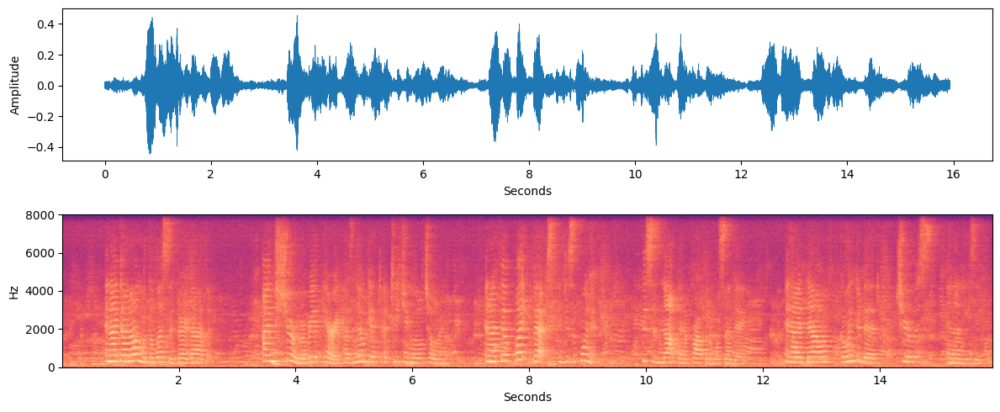

In [5]:
assert complete(), 'Subset quotas are incomplete. Return to cell 3.'
train=manifest[manifest.split=='train'].copy()
test=manifest[manifest.split=='test'].copy()
assert set(train.speaker).isdisjoint(set(test.speaker)), 'Speaker overlap found.'
assert set(train.source_id).isdisjoint(set(test.source_id)), 'Source overlap found.'
assert all((part.label==c).sum()>=5 for part in [train,test] for c in LABELS)
def read_audio(path,max_seconds=None):
    with sf.SoundFile(path) as f:
        sr=f.samplerate
        audio=f.read(frames=-1 if max_seconds is None else int(sr*max_seconds),dtype='float32',always_2d=True).mean(axis=1)
    if sr!=16000: audio=librosa.resample(audio,orig_sr=sr,target_sr=16000)
    return np.asarray(audio,dtype=np.float32),16000
example=test.iloc[0]
audio,sr=read_audio(example.path)
print('File:',Path(example.path).name,'Condition:',NAMES[example.label])
print('Sample rate:',sr,'Duration:',len(audio)/sr)
display(Audio(audio,rate=sr))
fig,axs=plt.subplots(2,1,figsize=(12,5))
axs[0].plot(np.arange(len(audio))/sr,audio,lw=.5); axs[0].set(xlabel='Seconds',ylabel='Amplitude')
axs[1].specgram(audio,NFFT=512,Fs=sr,noverlap=384,cmap='magma'); axs[1].set(xlabel='Seconds',ylabel='Hz')
fig.tight_layout(); fig.savefig(OUT/'example_audio.png',dpi=160); plt.show()

## 5 Background features

<div dir="ltr" lang="en">Compute MFCC mean/standard deviation plus spectral centroid, bandwidth, rolloff, zero crossing rate and RMS statistics. Use the first 10 seconds consistently for classification. Filenames, class names and speaker IDs are never input features.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نستخرج متوسط وانحراف معاملات الطيف الميلية وخصائص طيفية وطاقة ومعدل عبور الصفر. نستخدم أول عشر ثوانٍ بصورة موحدة للتصنيف. أسماء الملفات والفئات والمتحدثين لا تدخل ضمن خصائص النموذج.</div>

In [6]:
def features(path):
    a,sr=read_audio(path,10)
    if len(a)<512: raise ValueError('Audio too short: '+path)
    kw=dict(y=a,n_fft=512,hop_length=160)
    blocks=[librosa.feature.mfcc(y=a,sr=sr,n_mfcc=20,n_fft=512,hop_length=160),
            librosa.feature.spectral_centroid(sr=sr,**kw),librosa.feature.spectral_bandwidth(sr=sr,**kw),
            librosa.feature.spectral_rolloff(sr=sr,**kw),
            librosa.feature.zero_crossing_rate(a,frame_length=512,hop_length=160),
            librosa.feature.rms(y=a,frame_length=512,hop_length=160)]
    return np.concatenate([np.r_[b.mean(axis=1),b.std(axis=1)] for b in blocks])
X_train=np.stack([features(p) for p in tqdm(train.path,desc='Training features')])
X_test=np.stack([features(p) for p in tqdm(test.path,desc='Test features')])
y_train=train.label.to_numpy(); y_test=test.label.to_numpy()
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
print('Train:',X_train.shape,'Test:',X_test.shape)

Training features:   0%|          | 0/80 [00:00<?, ?it/s]

Test features:   0%|          | 0/40 [00:00<?, ?it/s]

Train: (80, 50) Test: (40, 50)


## 6 Train background classifiers

<div dir="ltr" lang="en">Compare SVM and Random Forest on the fixed original split. This is background condition classification with recording-level labels, not temporal event localization. No model selection is based on test scores.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نقارن مصنف المتجهات الداعمة والغابة العشوائية باستخدام التقسيم الأصلي الثابت. المهمة تصنيف خلفية التسجيل وليست تحديد أوقات الأحداث. لا نضبط المعلمات اعتمادًا على نتائج الاختبار.</div>

In [ ]:
models={'SVM':make_pipeline(StandardScaler(),SVC(C=1,kernel='rbf',class_weight='balanced')),
        'Random Forest':RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=SEED,n_jobs=-1)}
results=[]; predictions={}
for name,model in models.items():
    start=time.perf_counter(); model.fit(X_train,y_train); elapsed=time.perf_counter()-start
    pred=model.predict(X_test); predictions[name]=pred
    results.append(dict(model=name,accuracy=accuracy_score(y_test,pred),macro_f1=f1_score(y_test,pred,average='macro'),fit_seconds=elapsed))
    report=classification_report(y_test,pred,labels=LABELS,target_names=[NAMES[c] for c in LABELS],zero_division=0)
    print(name,'\n',report); (OUT/(name.replace(' ','_')+'_report.txt')).write_text(report)
results=pd.DataFrame(results); display(results); results.to_csv(OUT/'background_results.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,(name,pred) in zip(axs,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=LABELS,display_labels=LABELS,ax=ax,cmap='Blues',colorbar=False); ax.set_title(name)
fig.tight_layout(); fig.savefig(OUT/'background_confusion.png',dpi=170); plt.show()
test_predictions=test.copy()
for name,pred in predictions.items(): test_predictions[name]=pred
test_predictions.to_csv(OUT/'background_predictions.csv',index=False)

## 7 Load pretrained VAD

<div dir="ltr" lang="en">Load Silero without retraining. SoundFile supplies 16 kHz mono tensors, avoiding optional torchaudio decoding dependencies. VAD detects speech from any source; TV speech and babble can be valid detections.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نحمّل نموذج سيليرو الجاهز دون إعادة تدريب. نقرأ الصوت أحادي القناة بمعدل ستة عشر ألف عينة في الثانية، لتجنب مشاكل فك الصوت. النموذج يكشف الكلام من أي مصدر؛ كلام التلفزيون أو الثرثرة قد يُعد كشفًا صحيحًا.</div>

In [ ]:
from silero_vad import load_silero_vad, get_speech_timestamps
vad_model=load_silero_vad(); torch.set_num_threads(1)
VAD_THRESHOLD=0.5
VAD_MAX_SECONDS=30
vad_examples=pd.concat([test[test.label==c].head(2) for c in LABELS]).copy()
print('VAD files:',len(vad_examples),'Threshold:',VAD_THRESHOLD)

## 8 VAD timestamps plots and audio

<div dir="ltr" lang="en">Run VAD on up to 30 seconds per selected test recording. Save timestamps, figures and speech clips. Speech percentage is a descriptive output, not detection accuracy. Keep the threshold fixed before manual evaluation.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نطبق كشف الكلام على ثلاثين ثانية كحد أقصى لكل تسجيل مختار، ونحفظ أوقات الكلام والرسومات والمقاطع. نسبة زمن الكلام وصف للنتيجة وليست دقة للنموذج. نبقي العتبة ثابتة قبل التقييم اليدوي.</div>

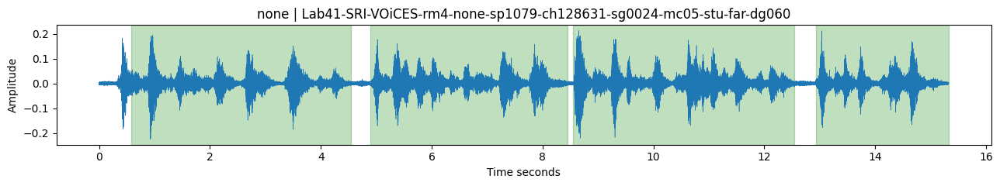

Original: none


First detected speech segment


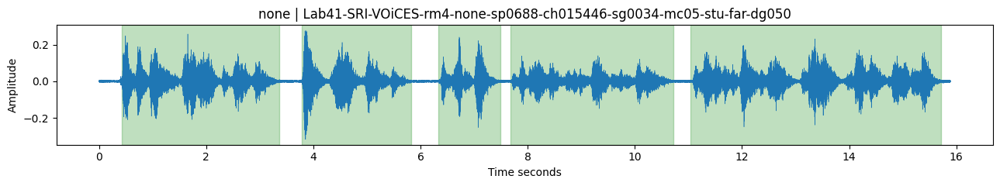

Original: none


First detected speech segment


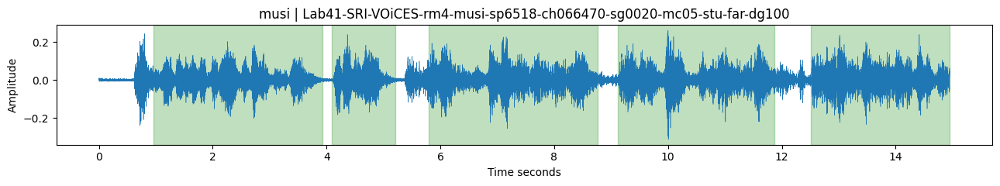

Original: musi


First detected speech segment


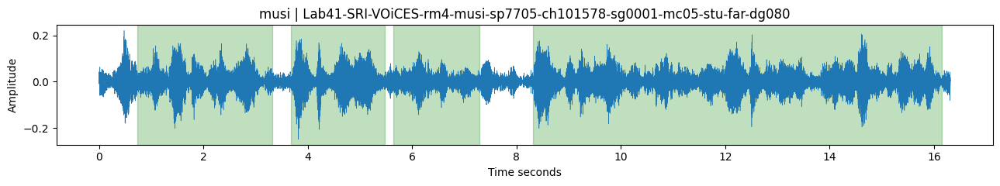

Original: musi


First detected speech segment


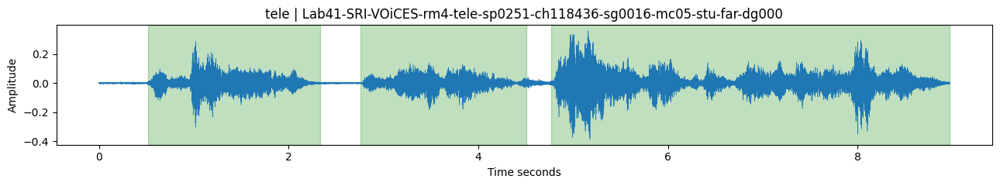

Original: tele


First detected speech segment


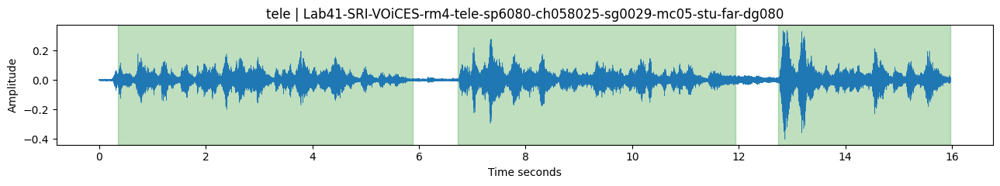

Original: tele


First detected speech segment


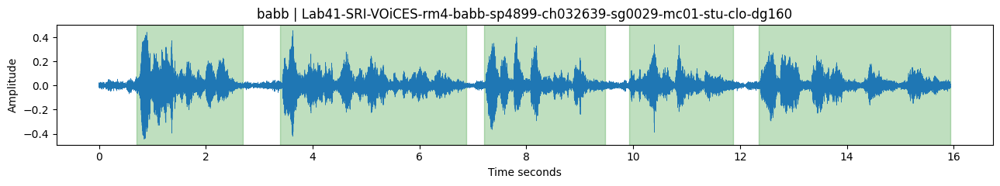

Original: babb


First detected speech segment


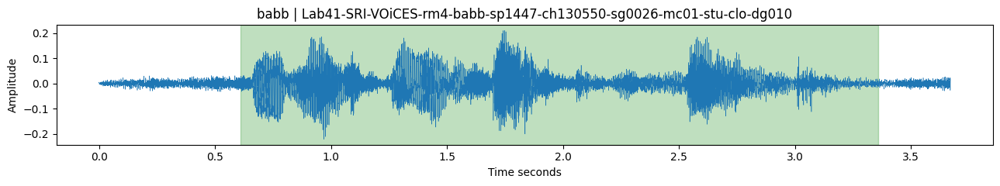

Original: babb


First detected speech segment


,file_id,label,duration,speech_seconds,speech_percent,segments
0,Lab41-SRI-VOiCES-rm4-none-sp1079-ch128631-sg00...,none,15.325,13.903,90.721044,4
1,Lab41-SRI-VOiCES-rm4-none-sp0688-ch015446-sg00...,none,15.890,13.836,87.073631,5
2,Lab41-SRI-VOiCES-rm4-musi-sp6518-ch066470-sg00...,musi,14.950,12.244,81.899666,5
3,Lab41-SRI-VOiCES-rm4-musi-sp7705-ch101578-sg00...,musi,16.315,13.872,85.026050,4
4,Lab41-SRI-VOiCES-rm4-tele-sp0251-ch118436-sg00...,tele,8.970,7.776,86.688963,3
5,Lab41-SRI-VOiCES-rm4-tele-sp6080-ch058025-sg00...,tele,15.970,13.976,87.514089,3
6,Lab41-SRI-VOiCES-rm4-babb-sp4899-ch032639-sg00...,babb,15.940,13.266,83.224592,5
7,Lab41-SRI-VOiCES-rm4-babb-sp1447-ch130550-sg00...,babb,3.670,2.748,74.877384,1


In [9]:
vad_rows=[]; vad_summary=[]; vad_cache={}
for row in vad_examples.itertuples():
    a,sr=read_audio(row.path,VAD_MAX_SECONDS)
    file_id=Path(row.path).stem
    stamps=get_speech_timestamps(torch.from_numpy(a),vad_model,sampling_rate=sr,threshold=VAD_THRESHOLD,return_seconds=False)
    vad_cache[file_id]=(a,sr,stamps,row.label)
    fig,ax=plt.subplots(figsize=(13,2.5)); ax.plot(np.arange(len(a))/sr,a,lw=.4)
    total=0
    for i,seg in enumerate(stamps):
        s,e=int(seg['start']),int(seg['end']); total+=e-s
        vad_rows.append(dict(file_id=file_id,label=row.label,start=s/sr,end=e/sr))
        ax.axvspan(s/sr,e/sr,color='green',alpha=.25)
        clip_dir=OUT/'speech_clips'; clip_dir.mkdir(exist_ok=True)
        sf.write(clip_dir/f'{file_id}_{i+1:02d}.wav',a[s:e],sr)
    ax.set(title=f'{row.label} | {file_id}',xlabel='Time seconds',ylabel='Amplitude')
    fig.tight_layout(); fig.savefig(OUT/f'{file_id}_vad.png',dpi=140); plt.show(); plt.close(fig)
    vad_summary.append(dict(file_id=file_id,label=row.label,duration=len(a)/sr,speech_seconds=total/sr,speech_percent=100*total/len(a),segments=len(stamps)))
    print('Original:',row.label); display(Audio(a,rate=sr))
    if stamps:
        first=stamps[0]; print('First detected speech segment')
        display(Audio(a[first['start']:first['end']],rate=sr))
vad_table=pd.DataFrame(vad_rows,columns=['file_id','label','start','end'])
vad_table.to_csv(OUT/'vad_timestamps.csv',index=False)
vad_summary=pd.DataFrame(vad_summary); vad_summary.to_csv(OUT/'vad_summary.csv',index=False)
display(vad_summary)

In [10]:
import base64
import io
import json
import uuid
import numpy as np
import soundfile as sf
from IPython.display import HTML, display

assert "vad_cache" in globals() and vad_cache, \
    "شغّل الخلية 8 أولًا حتى تتجهز التسجيلات ونتائج VAD."

players = []

for file_id, (audio, sr, stamps, label) in vad_cache.items():
    buffer = io.BytesIO()
    sf.write(buffer, audio, sr, format="WAV", subtype="PCM_16")

    # Waveform summary for fast browser drawing
    edges = np.linspace(
        0, len(audio), min(1800, len(audio)) + 1,
        dtype=int
    )

    lower, upper = [], []
    for start, end in zip(edges[:-1], edges[1:]):
        chunk = audio[start:end]
        lower.append(float(chunk.min()))
        upper.append(float(chunk.max()))

    players.append({
        "name": file_id,
        "label": label,
        "duration": len(audio) / sr,
        "audio": base64.b64encode(buffer.getvalue()).decode(),
        "lower": lower,
        "upper": upper,
        "speech": [
            [int(s["start"]) / sr, int(s["end"]) / sr]
            for s in stamps
        ]
    })

widget_id = "vad_" + uuid.uuid4().hex
payload = json.dumps(players).replace("</", "<\\/")

template = r"""
<div id="__ID__" style="
    font-family:Arial; padding:16px; border:1px solid #ccc;
    border-radius:10px; background:white; color:#222;">

  <div dir="rtl" style="text-align:right; margin-bottom:12px;">
    <b>متابعة الصوت على الموجة</b><br>
    اختار التسجيل واضغط تشغيل. اضغط على الموجة للانتقال إلى وقت معيّن.<br>
    الأخضر: كلام متوقّع — الأحمر: موقع التشغيل الحالي.
  </div>

  <select class="recording" style="width:100%; padding:8px;"></select>

  <div class="filename" dir="ltr"
       style="font-size:12px; overflow-wrap:anywhere; margin:10px 0;"></div>

  <audio class="audio" controls preload="metadata"
         style="width:100%;"></audio>

  <div style="margin:10px 0;" dir="rtl">
    سرعة التشغيل:
    <select class="speed">
      <option value="0.5">0.5×</option>
      <option value="0.75">0.75×</option>
      <option value="1" selected>1×</option>
    </select>
    <span class="clock" dir="ltr"
          style="display:inline-block; margin:0 15px;"></span>
  </div>

  <canvas class="wave" style="
      width:100%; height:240px; display:block;
      border:1px solid #ccc; cursor:crosshair;"></canvas>

  <div class="status" dir="rtl"
       style="text-align:right; margin-top:10px;"></div>
</div>

<script>
(() => {
  const data = __DATA__;
  const root = document.getElementById("__ID__");
  const select = root.querySelector(".recording");
  const audio = root.querySelector(".audio");
  const speed = root.querySelector(".speed");
  const canvas = root.querySelector(".wave");
  const ctx = canvas.getContext("2d");
  const clock = root.querySelector(".clock");
  const status = root.querySelector(".status");

  let current = data[0];

  data.forEach((item, i) => {
    const option = document.createElement("option");
    option.value = i;
    option.textContent = `${i + 1} — ${item.label} — ${item.name}`;
    select.appendChild(option);
  });

  function draw() {
    const w = canvas.clientWidth || 900;
    const h = 240;
    const ratio = window.devicePixelRatio || 1;

    if (canvas.width !== Math.round(w * ratio) ||
        canvas.height !== Math.round(h * ratio)) {
      canvas.width = Math.round(w * ratio);
      canvas.height = Math.round(h * ratio);
    }
    ctx.setTransform(ratio, 0, 0, ratio, 0, 0);

    const left = 38, right = w - 15;
    const top = 15, bottom = h - 35;
    const mid = (top + bottom) / 2;
    const plotWidth = right - left;
    const duration = current.duration;
    const x = t => left + (t / duration) * plotWidth;

    ctx.fillStyle = "#fff";
    ctx.fillRect(0, 0, w, h);

    ctx.fillStyle = "rgba(60,165,75,0.25)";
    current.speech.forEach(([start, end]) => {
      ctx.fillRect(x(start), top, x(end)-x(start), bottom-top);
    });

    ctx.strokeStyle = "#ddd";
    ctx.beginPath();
    ctx.moveTo(left, mid);
    ctx.lineTo(right, mid);
    ctx.stroke();

    const peak = Math.max(
      0.001,
      ...current.upper.map(Math.abs),
      ...current.lower.map(Math.abs)
    );
    const scale = (bottom-top) * 0.46 / peak;
    const count = current.lower.length;

    ctx.strokeStyle = "#1976b8";
    ctx.lineWidth = 1;
    ctx.beginPath();

    for (let i = 0; i < count; i++) {
      const px = left + ((i + 0.5) / count) * plotWidth;
      ctx.moveTo(px, mid - current.upper[i] * scale);
      ctx.lineTo(px, mid - current.lower[i] * scale);
    }
    ctx.stroke();

    const step = duration <= 6 ? 1 : 2;
    ctx.fillStyle = "#444";
    ctx.font = "12px Arial";
    ctx.textAlign = "center";

    for (let t = 0; t <= duration; t += step) {
      ctx.fillText(String(t), x(t), h-15);
    }

    const t = Math.min(audio.currentTime || 0, duration);
    ctx.strokeStyle = "#e32636";
    ctx.lineWidth = 2;
    ctx.beginPath();
    ctx.moveTo(x(t), top);
    ctx.lineTo(x(t), bottom);
    ctx.stroke();

    clock.textContent = `${t.toFixed(2)} / ${duration.toFixed(2)} s`;

    const speechNow = current.speech.some(
      ([start, end]) => t >= start && t < end
    );

    status.textContent = speechNow
      ? "الموقع الحالي أخضر: النموذج توقّع كلامًا هنا."
      : "الموقع الحالي أبيض: النموذج لم يكتشف كلامًا هنا.";
  }

  function loadRecording() {
    audio.pause();
    current = data[Number(select.value)];
    audio.src = "data:audio/wav;base64," + current.audio;
    audio.playbackRate = Number(speed.value);
    root.querySelector(".filename").textContent = current.name;
    draw();
  }

  select.addEventListener("change", loadRecording);
  speed.addEventListener("change", () => {
    audio.playbackRate = Number(speed.value);
  });

  canvas.addEventListener("click", event => {
    const rect = canvas.getBoundingClientRect();
    const fraction = (event.clientX - rect.left - 38) /
                     (rect.width - 53);
    audio.currentTime = Math.max(
      0, Math.min(current.duration, fraction * current.duration)
    );
    draw();
  });

  audio.addEventListener("timeupdate", draw);
  audio.addEventListener("seeked", draw);
  audio.addEventListener("loadedmetadata", draw);

  function animate() {
    if (!root.isConnected) return;
    if (!audio.paused) draw();
    requestAnimationFrame(animate);
  }

  new ResizeObserver(draw).observe(canvas);
  loadRecording();
  animate();
})();
</script>
"""

html = template.replace("__ID__", widget_id).replace("__DATA__", payload)
display(HTML(html))

## 9 Optional manual VAD reference

<div dir="ltr" lang="en">No verified frame-level speech reference has been supplied to this notebook. Therefore it does not claim VAD accuracy. To evaluate, independently annotate complete clips by listening, then save a CSV with file_id,start,end. Include every reviewed file in REVIEWED_FILES, even a file containing no speech. Do not copy predicted intervals into the reference.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">لم نوفر مرجعًا زمنيًا موثقًا للكلام، لذلك لا ندّعي دقة رقمية لكشف الكلام. للتقييم استمع للمقطع كاملًا وحدد فترات الكلام بصورة مستقلة واحفظها بجدول. أضف كل ملف راجعته إلى قائمة الملفات المراجعة، حتى لو لم يحتوي كلامًا. لا تنسخ توقعات النموذج باعتبارها مرجعًا.</div>

In [11]:
REFERENCE_CSV=Path('/content/manual_vad_reference.csv')
REVIEWED_FILES=[]  # Exact file_id strings for fully annotated clips
pd.DataFrame(columns=['file_id','start','end']).to_csv(OUT/'manual_reference_template.csv',index=False)
print('Available file IDs:')
print('\n'.join(vad_cache))
print('Optional: provide an independently annotated CSV and fill REVIEWED_FILES.')

Available file IDs:
Lab41-SRI-VOiCES-rm4-none-sp1079-ch128631-sg0024-mc05-stu-far-dg060
Lab41-SRI-VOiCES-rm4-none-sp0688-ch015446-sg0034-mc05-stu-far-dg050
Lab41-SRI-VOiCES-rm4-musi-sp6518-ch066470-sg0020-mc05-stu-far-dg100
Lab41-SRI-VOiCES-rm4-musi-sp7705-ch101578-sg0001-mc05-stu-far-dg080
Lab41-SRI-VOiCES-rm4-tele-sp0251-ch118436-sg0016-mc05-stu-far-dg000
Lab41-SRI-VOiCES-rm4-tele-sp6080-ch058025-sg0029-mc05-stu-far-dg080
Lab41-SRI-VOiCES-rm4-babb-sp4899-ch032639-sg0029-mc01-stu-clo-dg160
Lab41-SRI-VOiCES-rm4-babb-sp1447-ch130550-sg0026-mc01-stu-clo-dg010
Optional: provide an independently annotated CSV and fill REVIEWED_FILES.


## 10 Optional quantitative VAD evaluation

<div dir="ltr" lang="en">When independent annotations are available, compare masks at 10 ms resolution. Report per-file precision, recall and F1 plus pooled metrics. Without annotations this cell skips evaluation rather than inventing scores. Reference timing and annotation reliability limit the conclusions.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">عند توفر توثيق يدوي مستقل نقارن وجود الكلام كل عشرة أجزاء من الألف من الثانية، ونحسب المقاييس لكل ملف وللمجموع. بدون مرجع نتجاوز الحساب ولا نختلق نتائج. دقة التوقيت وجودة التوثيق تحدان من الاستنتاج.</div>

In [12]:
from sklearn.metrics import precision_recall_fscore_support
if REFERENCE_CSV.exists() and REVIEWED_FILES:
    ref=pd.read_csv(REFERENCE_CSV)
    assert {'file_id','start','end'}<=set(ref.columns)
    metrics=[]; all_true=[]; all_pred=[]
    for file_id in REVIEWED_FILES:
        assert file_id in vad_cache, 'Unknown file ID: '+file_id
        a,sr,stamps,label=vad_cache[file_id]
        centers=np.arange(.005,len(a)/sr,.01)
        truth=np.zeros(len(centers),dtype=int); pred=np.zeros_like(truth)
        for r in ref[ref.file_id==file_id].itertuples():
            assert 0<=r.start<r.end<=len(a)/sr+1e-6
            truth[(centers>=r.start)&(centers<r.end)]=1
        for seg in stamps: pred[(centers>=seg['start']/sr)&(centers<seg['end']/sr)]=1
        pr,rc,f1,_=precision_recall_fscore_support(truth,pred,average='binary',zero_division=0)
        metrics.append(dict(file_id=file_id,precision=pr,recall=rc,f1=f1))
        all_true.extend(truth); all_pred.extend(pred)
    scores=pd.DataFrame(metrics); display(scores); scores.to_csv(OUT/'vad_manual_metrics.csv',index=False)
    print('Pooled speech classification metrics:')
    print(classification_report(all_true,all_pred,labels=[0,1],target_names=['Non-speech','Speech'],zero_division=0))
    shutil.copyfile(REFERENCE_CSV,OUT/'manual_vad_reference.csv')
else:
    print('VAD evaluated qualitatively only: no independent reference supplied.')

VAD evaluated qualitatively only: no independent reference supplied.


## 11 Summary and export

<div dir="ltr" lang="en">Export measured background results, VAD timestamps, audio clips, configuration and a manifest. Background condition labels are not temporal event annotations; manual VAD scores, if present, describe only reviewed clips. Inspect errors before writing the report.</div>

<div dir="rtl" lang="ar" style="text-align:right; line-height:1.8">نحفظ نتائج تصنيف الخلفية وأوقات الكلام والمقاطع والإعدادات وفهرس العينة. تسميات الخلفية لا تمثل توثيقًا زمنيًا للأحداث، وأي تقييم يدوي يخص المقاطع المراجعة فقط. نراجع الأخطاء قبل كتابة التقرير.</div>

In [13]:
config=dict(seed=SEED,archive_url=ARCHIVE_URL,targets=TARGET,classes=NAMES,
    task_a='Recording-level background condition classification, not temporal event localization',
    task_b='Pretrained Silero VAD, qualitative unless independent reference provided',
    vad_threshold=VAD_THRESHOLD,vad_max_seconds=VAD_MAX_SECONDS,
    classification_max_seconds=10,training_files=len(train),test_files=len(test),
    manual_reviewed_files=REVIEWED_FILES,python=platform.python_version(),torch=torch.__version__)
(OUT/'configuration.json').write_text(json.dumps(config,indent=2))
print('Background classification results:'); display(results)
print('VAD is speech from any source, including background speech.')
print('Next: review confusion matrices and VAD clips, then write the report.')
zip_path=shutil.make_archive('/content/VOICES_results','zip',root_dir=OUT)
from google.colab import files
files.download(zip_path)

Background classification results:


,model,accuracy,macro_f1,fit_seconds
0,SVM,0.55,0.519596,0.009004
1,Random Forest,0.50,0.492026,0.443072


VAD is speech from any source, including background speech.
Next: review confusion matrices and VAD clips, then write the report.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>